# Machine Learning Midterm — wine
All numbered sections follow the assignment. All experiments use fixed test indices and three train/validation seeds.

In [1]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, sklearn, sys
from pathlib import Path
from sklearn.datasets import load_breast_cancer,load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report,confusion_matrix,ConfusionMatrixDisplay,roc_curve,auc,adjusted_rand_score,silhouette_score
from sklearn.preprocessing import label_binarize
from sklearn.impute import SimpleImputer
from IPython.display import display
SEEDS=[42,52,62]; ROOT=Path('.'); FIG=ROOT/'figures';FIG.mkdir(exist_ok=True)
print('Versions:',sys.version.split()[0], 'sklearn',sklearn.__version__,'pandas',pd.__version__,'numpy',np.__version__)
def savefig(name):
 plt.tight_layout();plt.savefig(FIG/name,dpi=125,bbox_inches='tight');plt.show();plt.close()
def scores(model,X,y,dataset):
 pred=model.predict(X); prob=model.predict_proba(X)
 classes=model.classes_
 if dataset=='breast_cancer':
  roc=roc_auc_score((np.asarray(y)==0).astype(int),prob[:,list(classes).index(0)])
 else: roc=roc_auc_score(y,prob,labels=classes,multi_class='ovr',average='macro')
 return dict(accuracy=accuracy_score(y,pred),precision=precision_score(y,pred,average='macro',zero_division=0),recall=recall_score(y,pred,average='macro',zero_division=0),f1=f1_score(y,pred,average='macro',zero_division=0),auc=roc)
def make_model(algo,param,seed):
 if algo=='tree':return DecisionTreeClassifier(max_depth=param,random_state=seed)
 if algo=='knn':return KNeighborsClassifier(n_neighbors=param,weights='uniform',metric='euclidean')
 return GaussianNB()
def sil(X,labels):
 n=len(np.unique(labels))
 return silhouette_score(X,labels) if 1<n<len(labels) else np.nan


Versions: 3.11.4 sklearn 1.8.0 pandas 2.2.3 numpy 2.3.5


## 1. Loading the Datasets

In [2]:
dataset='wine'
bunch=load_breast_cancer() if dataset=='breast_cancer' else load_wine()
X=pd.DataFrame(bunch.data,columns=bunch.feature_names);y=pd.Series(bunch.target,index=X.index,name='target')
print('Shape:',X.shape,'Labels:',sorted(y.unique()),'Names:',list(bunch.target_names));print('Class counts:',y.value_counts().sort_index().to_dict());print('Features:',list(X.columns));display(X.head())
print('Interpretation: Features and original target labels are separate. Breast cancer class 0 means malignant and class 1 benign.' if dataset=='breast_cancer' else 'Interpretation: Wine retains its original classes 0, 1 and 2.')

Shape: (178, 13) Labels: [np.int64(0), np.int64(1), np.int64(2)] Names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Class counts: {0: 59, 1: 71, 2: 48}
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Interpretation: Wine retains its original classes 0, 1 and 2.


## 2. Dataset Quality Checks

In [3]:
print('Missing per column:');display(X.isna().sum().to_frame('missing'));print('Duplicate feature rows:',X.duplicated().sum());display(X.dtypes.to_frame('dtype'));print('Numerical:',X.select_dtypes(include='number').shape[1],'Categorical:',X.select_dtypes(exclude='number').shape[1]);q1=X.quantile(.25);q3=X.quantile(.75);iqr=q3-q1;out=((X.lt(q1-1.5*iqr))|(X.gt(q3+1.5*iqr))).sum();display(out.to_frame('IQR potential outliers'));print('Interpretation: IQR flags extreme observations, not necessarily errors; no rows are deleted. Extremes may affect distances, scaling and fitted boundaries.')

Missing per column:


,missing
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


Duplicate feature rows: 0


,dtype
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


Numerical: 13 Categorical: 0


,IQR potential outliers
alcohol,0
malic_acid,3
ash,3
alcalinity_of_ash,4
magnesium,4
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,2
color_intensity,4


Interpretation: IQR flags extreme observations, not necessarily errors; no rows are deleted. Extremes may affect distances, scaling and fitted boundaries.


## 3. Exploratory Data Analysis (EDA)

,mean,median,min,max,std,Q1,Q3
alcohol,13.000618,13.050,11.03,14.83,0.811827,12.3625,13.6775
malic_acid,2.336348,1.865,0.74,5.80,1.117146,1.6025,3.0825
ash,2.366517,2.360,1.36,3.23,0.274344,2.2100,2.5575
alcalinity_of_ash,19.494944,19.500,10.60,30.00,3.339564,17.2000,21.5000
magnesium,99.741573,98.000,70.00,162.00,14.282484,88.0000,107.0000
total_phenols,2.295112,2.355,0.98,3.88,0.625851,1.7425,2.8000
flavanoids,2.029270,2.135,0.34,5.08,0.998859,1.2050,2.8750
nonflavanoid_phenols,0.361854,0.340,0.13,0.66,0.124453,0.2700,0.4375
proanthocyanins,1.590899,1.555,0.41,3.58,0.572359,1.2500,1.9500
color_intensity,5.058090,4.690,1.28,13.00,2.318286,3.2200,6.2000


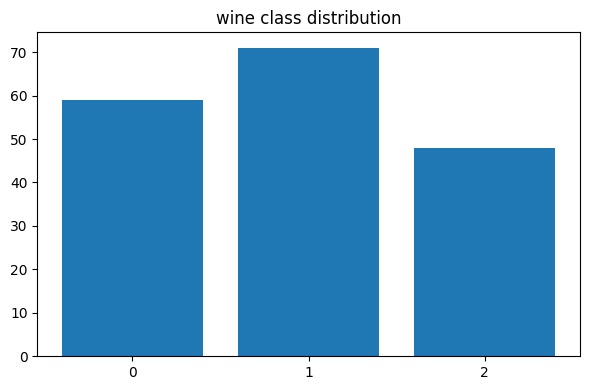

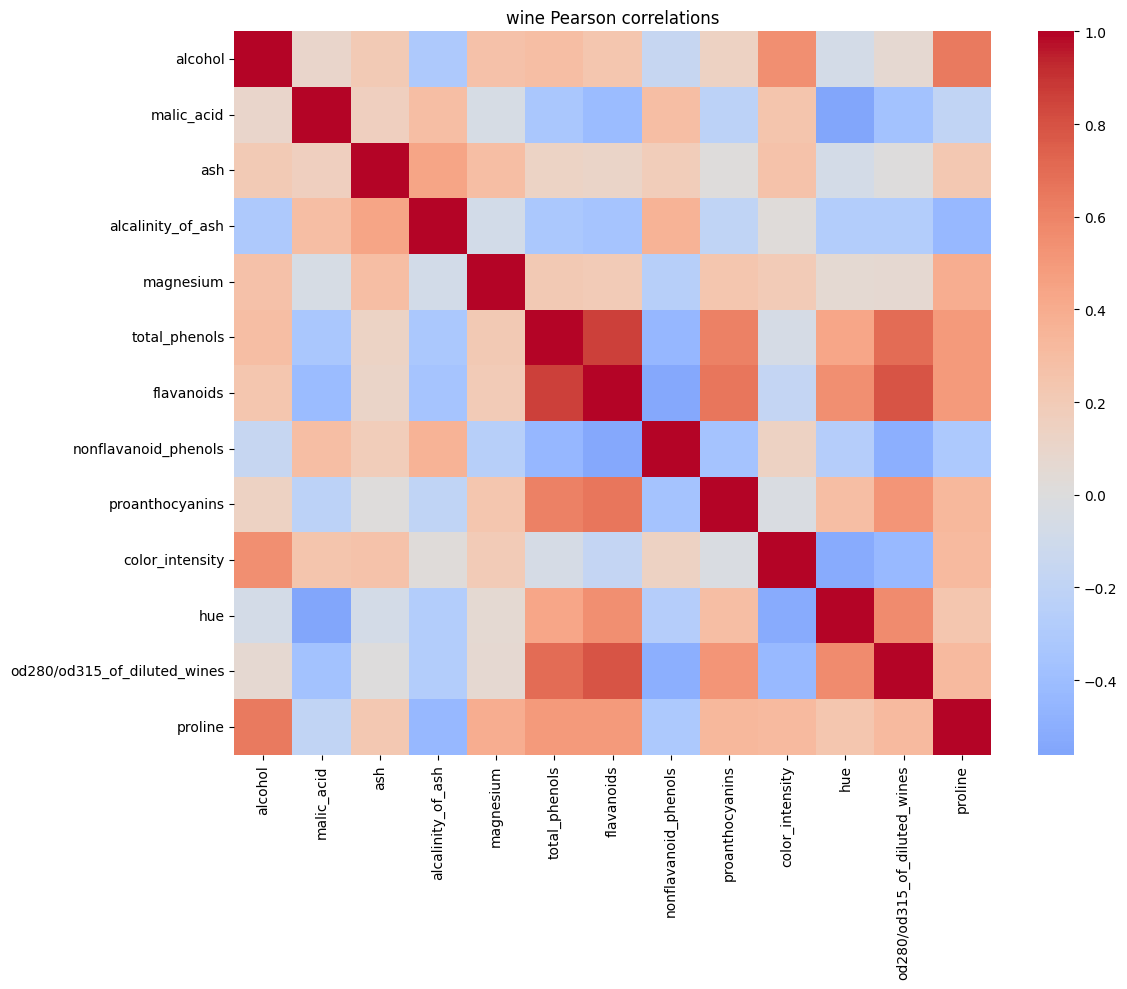

Top three unique absolute correlation pairs:


total_phenols  flavanoids                      0.864564
flavanoids     od280/od315_of_diluted_wines    0.787194
total_phenols  od280/od315_of_diluted_wines    0.699949
dtype: float64

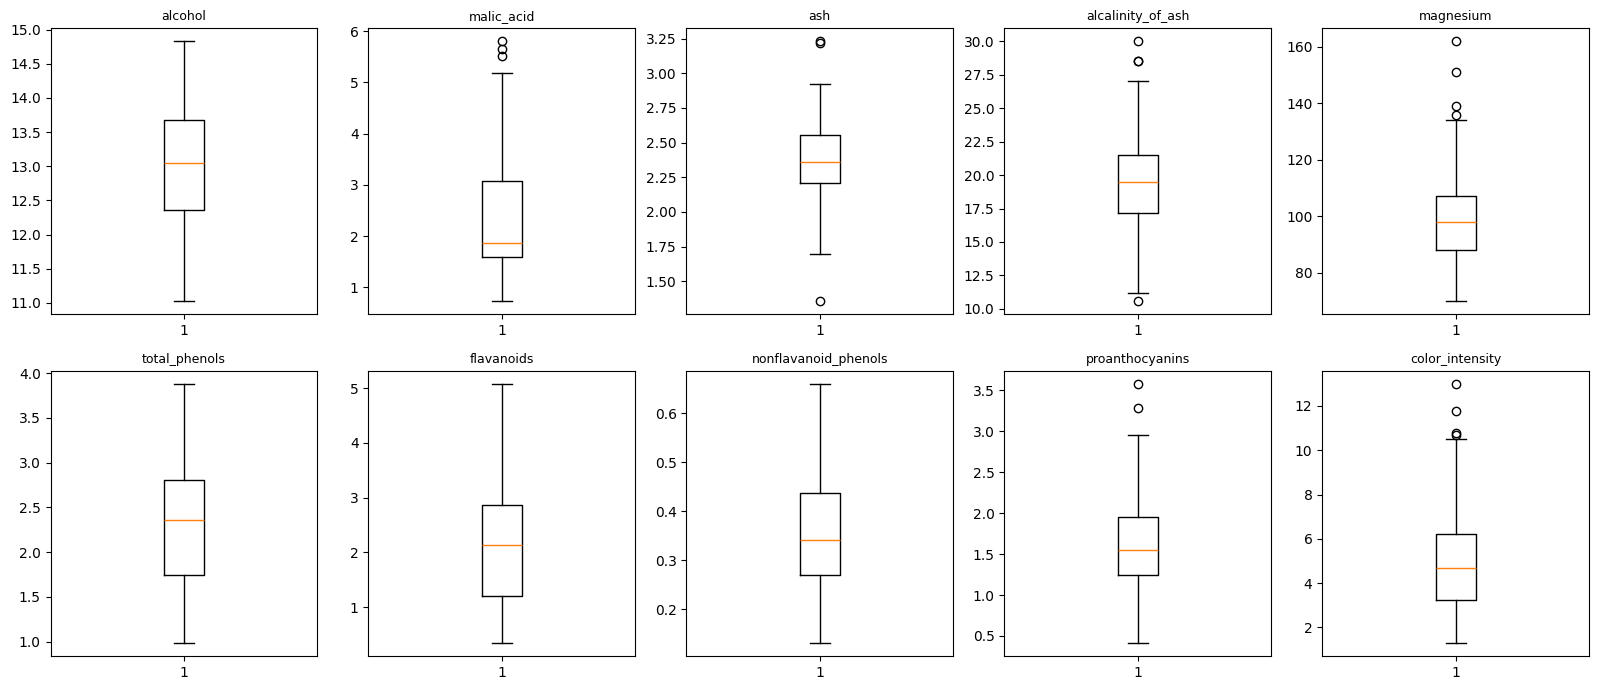

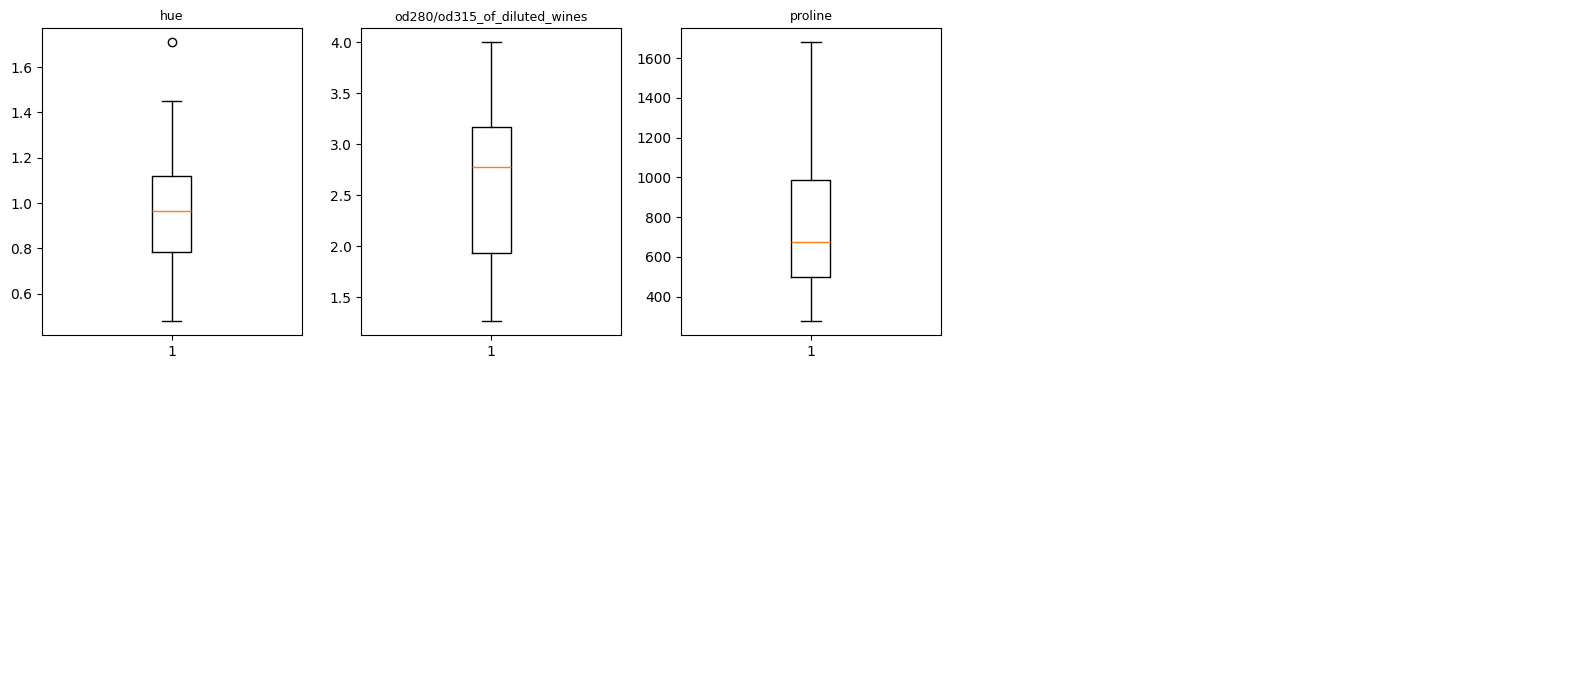

Interpretation: Feature ranges differ substantially, and boxplots flag possible outliers. Large-scale features can dominate Euclidean distances. EDA is descriptive and does not guide feature selection.


In [4]:
desc=X.describe().T[['mean','50%','min','max','std','25%','75%']].rename(columns={'50%':'median','25%':'Q1','75%':'Q3'});display(desc)
fig,ax=plt.subplots(figsize=(6,4));ax.bar(y.value_counts().sort_index().index.astype(str),y.value_counts().sort_index().values);ax.set_title(dataset+' class distribution');savefig(dataset+'_class_distribution.png')
corr=X.corr();fig,ax=plt.subplots(figsize=(12,10));sns.heatmap(corr,ax=ax,cmap='coolwarm',center=0);ax.set_title(dataset+' Pearson correlations');savefig(dataset+'_correlations.png')
upper=corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack();top=upper.reindex(upper.abs().sort_values(ascending=False).index).head(3);print('Top three unique absolute correlation pairs:');display(top)
for i in range(0,X.shape[1],10):
 cols=X.columns[i:i+10];fig,axes=plt.subplots(2,5,figsize=(16,7));
 for ax,col in zip(axes.flat,cols):ax.boxplot(X[col].to_numpy());ax.set_title(col,fontsize=9)
 for ax in list(axes.flat)[len(cols):]:ax.axis('off')
 savefig(f'{dataset}_boxplots_{i//10+1}.png')
print('Interpretation: Feature ranges differ substantially, and boxplots flag possible outliers. Large-scale features can dominate Euclidean distances. EDA is descriptive and does not guide feature selection.')

## 4. Splitting the Datasets

In [5]:
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
splits={};split_rows=[]
for seed in SEEDS:
 a,b,ya,yb=train_test_split(X_dev,y_dev,test_size=.125,stratify=y_dev,random_state=seed)
 splits[seed]=dict(X_train=a,X_val=b,y_train=ya,y_val=yb,X_test=X_test,y_test=y_test)
 assert not(set(a.index)&set(b.index) or set(a.index)&set(X_test.index) or set(b.index)&set(X_test.index))
 assert len(a)+len(b)+len(X_test)==len(X)
 for name,xx,yy in [('train',a,ya),('validation',b,yb),('test',X_test,y_test)]:split_rows.append(dict(seed=seed,subset=name,count=len(xx),percent=100*len(xx)/len(X),class_counts=str(yy.value_counts().sort_index().to_dict())))
display(pd.DataFrame(split_rows));print('Fixed test indices:',list(X_test.index));print('Training and validation indices per seed:')
for seed,s in splits.items():print(seed,'train',list(s['X_train'].index),'validation',list(s['X_val'].index))
assert all(s['X_test'].index.equals(X_test.index) for s in splits.values())
print('Interpretation: The test set is identical for all seeds; only train/validation membership changes.')

,seed,subset,count,percent,class_counts
0,42,train,124,69.662921,"{0: 41, 1: 50, 2: 33}"
1,42,validation,18,10.112360,"{0: 6, 1: 7, 2: 5}"
2,42,test,36,20.224719,"{0: 12, 1: 14, 2: 10}"
3,52,train,124,69.662921,"{0: 41, 1: 50, 2: 33}"
4,52,validation,18,10.112360,"{0: 6, 1: 7, 2: 5}"
5,52,test,36,20.224719,"{0: 12, 1: 14, 2: 10}"
6,62,train,124,69.662921,"{0: 41, 1: 50, 2: 33}"
7,62,validation,18,10.112360,"{0: 6, 1: 7, 2: 5}"
8,62,test,36,20.224719,"{0: 12, 1: 14, 2: 10}"


Fixed test indices: [10, 134, 28, 121, 62, 51, 7, 66, 129, 166, 102, 143, 42, 130, 14, 108, 105, 20, 100, 38, 93, 60, 22, 18, 98, 64, 58, 132, 112, 155, 48, 176, 94, 177, 164, 173]
Training and validation indices per seed:
42 train [163, 148, 116, 122, 115, 147, 46, 141, 57, 168, 36, 159, 103, 29, 23, 68, 101, 50, 11, 113, 114, 34, 27, 125, 165, 49, 74, 83, 162, 31, 30, 25, 44, 149, 26, 9, 63, 13, 77, 24, 142, 85, 144, 109, 41, 71, 78, 16, 92, 47, 90, 96, 150, 69, 133, 138, 91, 124, 15, 126, 139, 140, 95, 82, 56, 40, 12, 161, 99, 61, 136, 170, 156, 3, 154, 104, 37, 111, 53, 135, 76, 106, 32, 118, 119, 43, 21, 80, 65, 72, 153, 17, 67, 128, 146, 175, 55, 84, 73, 117, 70, 127, 8, 88, 87, 59, 54, 39, 45, 2, 81, 19, 174, 171, 52, 137, 167, 5, 151, 107, 131, 152, 172, 75] validation [157, 145, 158, 110, 6, 120, 0, 89, 123, 33, 79, 35, 1, 97, 4, 86, 169, 160]
52 train [128, 135, 53, 27, 172, 141, 169, 11, 131, 79, 111, 83, 75, 115, 86, 84, 12, 87, 4, 89, 147, 126, 0, 55, 36, 67, 13, 24, 127, 

## 5. Data Preprocessing and Scaling

In [6]:
prepared={};has_missing=X.isna().any().any()
for seed,s in splits.items():
 train=s['X_train'].copy();val=s['X_val'].copy();test=s['X_test'].copy()
 imputer=None
 if has_missing:
  imputer=SimpleImputer(strategy='median');train=pd.DataFrame(imputer.fit_transform(train),columns=X.columns,index=train.index);val=pd.DataFrame(imputer.transform(val),columns=X.columns,index=val.index);test=pd.DataFrame(imputer.transform(test),columns=X.columns,index=test.index)
 scaler=StandardScaler();scaled_train=pd.DataFrame(scaler.fit_transform(train),columns=X.columns,index=train.index);scaled_val=pd.DataFrame(scaler.transform(val),columns=X.columns,index=val.index);scaled_test=pd.DataFrame(scaler.transform(test),columns=X.columns,index=test.index)
 prepared[seed]={'unscaled':(train,val,test),'scaled':(scaled_train,scaled_val,scaled_test),'scaler':scaler,'imputer':imputer}
print('Missing data:',has_missing,'; six independent scalers across two notebooks, one per dataset/seed.')
display(prepared[42]['unscaled'][0].head());display(prepared[42]['scaled'][0].head())
print('Interpretation: StandardScaler centers training columns and divides by training standard deviations; validation and test reuse these training-fitted parameters.')

Missing data: False ; six independent scalers across two notebooks, one per dataset/seed.


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


Interpretation: StandardScaler centers training columns and divides by training standard deviations; validation and test reuse these training-fitted parameters.


## 6. Preparing the Two Data Representations

In [7]:
print('Both original and StandardScaler-transformed features retained for each seed, with identical indices.');assert all(prepared[s]['unscaled'][0].index.equals(prepared[s]['scaled'][0].index) for s in SEEDS)

Both original and StandardScaler-transformed features retained for each seed, with identical indices.


## 7. Training the Classification Models

## 8. Measuring Validation Performance

### Classifier Configuration Comparison

This section compares classifier configurations using validation results from three random seeds. Models are ranked primarily by mean validation macro-F1. The held-out test set is not used for model selection.

,dataset,run_id,configuration_id,seed,algorithm,representation,parameter,train_accuracy,train_f1,val_accuracy,val_precision,val_recall,val_f1,val_auc
0,wine,wine_tree_unscaled_2_s42,wine_tree_unscaled_2,42,tree,unscaled,2,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,0.910596
1,wine,wine_tree_unscaled_3_s42,wine_tree_unscaled_3,42,tree,unscaled,3,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,0.968645
2,wine,wine_tree_unscaled_5_s42,wine_tree_unscaled_5,42,tree,unscaled,5,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
3,wine,wine_tree_unscaled_10_s42,wine_tree_unscaled_10,42,tree,unscaled,10,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
4,wine,wine_tree_unscaled_none_s42,wine_tree_unscaled_none,42,tree,unscaled,None,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,wine,wine_knn_scaled_3_s62,wine_knn_scaled_3,62,knn,scaled,3,0.959677,0.960888,0.888889,0.896825,0.904762,0.888500,1.000000
62,wine,wine_knn_scaled_5_s62,wine_knn_scaled_5,62,knn,scaled,5,0.975806,0.975871,0.944444,0.944444,0.952381,0.944056,1.000000
63,wine,wine_knn_scaled_7_s62,wine_knn_scaled_7,62,knn,scaled,7,0.967742,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000
64,wine,wine_knn_scaled_11_s62,wine_knn_scaled_11,62,knn,scaled,11,0.967742,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000


,dataset,configuration_id,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_f1_mean,train_f1_std,val_accuracy_mean,val_accuracy_std,val_precision_mean,val_precision_std,val_recall_mean,val_recall_std,val_f1_mean,val_f1_std,val_auc_mean,val_auc_std
0,wine,wine_knn_scaled_11,knn,scaled,11,0.965054,0.004656,0.965589,0.004817,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
1,wine,wine_knn_scaled_5,knn,scaled,5,0.975806,0.000000,0.976174,0.000524,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
2,wine,wine_knn_scaled_7,knn,scaled,7,0.959677,0.008065,0.960288,0.007956,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
3,wine,wine_knn_scaled_1,knn,scaled,1,1.000000,0.000000,1.000000,0.000000,0.962963,0.032075,0.968254,0.027493,0.968254,0.027493,0.965812,0.029608,0.974868,0.021765
4,wine,wine_gnb_scaled_default,gnb,scaled,default,0.983871,0.000000,0.983960,0.000491,0.962963,0.032075,0.967593,0.028912,0.965608,0.030047,0.963844,0.031359,1.000000,0.000000
5,wine,wine_gnb_unscaled_default,gnb,unscaled,default,0.983871,0.000000,0.983960,0.000491,0.962963,0.032075,0.967593,0.028912,0.965608,0.030047,0.963844,0.031359,1.000000,0.000000
6,wine,wine_tree_scaled_10,tree,scaled,10,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
7,wine,wine_tree_scaled_3,tree,scaled,3,0.991935,0.000000,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103
8,wine,wine_tree_scaled_5,tree,scaled,5,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
9,wine,wine_tree_scaled_none,tree,scaled,None,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735


SELECTED FROM VALIDATION: wine_knn_scaled_11
Interpretation: Ranking uses mean validation macro-F1, then mean accuracy, lower sample F1 SD, then alphabetical ID. Test data are not used.


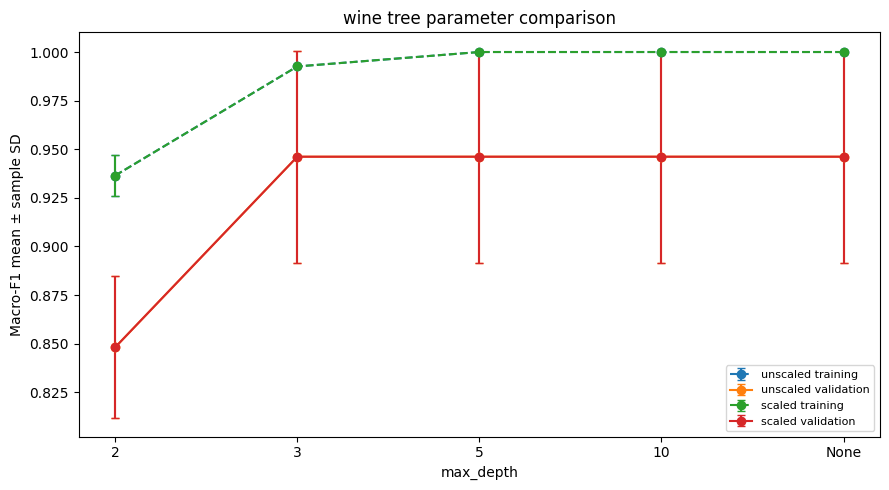

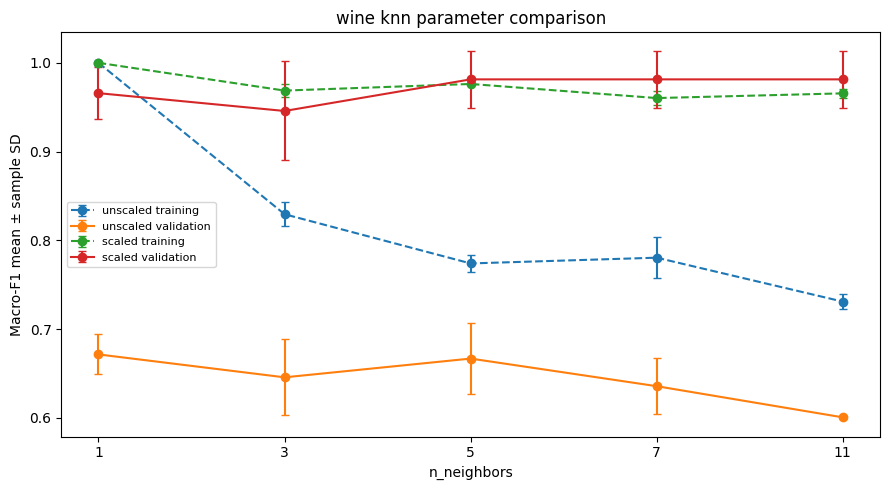

Interpretation: For the Wine dataset, the selected configuration is KNN with k=11 using scaled features. Its mean validation macro-F1 across three seeds is approximately 0.9814, with a sample standard deviation of 0.0323. The training and validation curves help compare model complexity and possible overfitting. The error bars represent variability across three overlapping train-validation splits, not independent test experiments.


In [8]:
configs=[('tree',d) for d in [2,3,5,10,None]]+[('knn',k) for k in [1,3,5,7,11]]+[('gnb','default')]
runs=[];fitted={}
for seed in SEEDS:
 for representation in ['unscaled','scaled']:
  a,b,_=prepared[seed][representation];ya=splits[seed]['y_train'];yb=splits[seed]['y_val']
  for algo,param in configs:
   cfg=f'{dataset}_{algo}_{representation}_{str(param).lower()}'
   model=make_model(algo,param,seed);model.fit(a,ya)
   if seed==42:fitted[(algo,representation,str(param))]=model
   tr=scores(model,a,ya,dataset);va=scores(model,b,yb,dataset)
   for c in np.unique(yb):
    actual=(yb==c).sum();pred=(model.predict(b)==c).sum();tp=((yb==c)&(model.predict(b)==c)).sum()
    if pred==0 or (actual>0 and tp==0 and pred==0):print('Undefined class precision before zero_division replacement:',cfg,seed,c)
   runs.append(dict(dataset=dataset,run_id=cfg+'_s'+str(seed),configuration_id=cfg,seed=seed,algorithm=algo,representation=representation,parameter=str(param),train_accuracy=tr['accuracy'],train_f1=tr['f1'],**{'val_'+k:v for k,v in va.items()}))
run_df=pd.DataFrame(runs);assert len(run_df)==66;display(run_df)
metrics=['train_accuracy','train_f1','val_accuracy','val_precision','val_recall','val_f1','val_auc']
summary=run_df.groupby(['dataset','configuration_id','algorithm','representation','parameter'],as_index=False)[metrics].agg(['mean','std']);summary.columns=['_'.join(filter(None,map(str,c))) for c in summary.columns.to_flat_index()];summary=summary.rename(columns={c:c[:-1] for c in summary.columns if c.endswith('_')});assert len(summary)==22
summary=summary.sort_values(['val_f1_mean','val_accuracy_mean','val_f1_std','configuration_id'],ascending=[False,False,True,True]).reset_index(drop=True)
display(summary);winner=summary.iloc[0];print('SELECTED FROM VALIDATION:',winner['configuration_id']);print('Interpretation: Ranking uses mean validation macro-F1, then mean accuracy, lower sample F1 SD, then alphabetical ID. Test data are not used.')
run_df.to_csv(ROOT/(dataset+'_classifier_runs.csv'),index=False)
summary.to_csv(ROOT/(dataset+'_classifier_summary.csv'),index=False)
run_df['parameter'] = run_df['parameter'].fillna('None')
summary['parameter'] = summary['parameter'].fillna('None')

run_df.to_csv(ROOT/(dataset+'_classifier_runs.csv'),index=False)
summary.to_csv(ROOT/(dataset+'_classifier_summary.csv'),index=False)
for algo,params,filename,xlabel in [('tree',[2,3,5,10,None],'tree_depth','max_depth'),('knn',[1,3,5,7,11],'knn_neighbors','n_neighbors')]:
 fig,ax=plt.subplots(figsize=(9,5))
 for rep in ['unscaled','scaled']:
  for col,label,style in [('train_f1','training','--'),('val_f1','validation','-')]:
   ss=summary[(summary.algorithm==algo)&(summary.representation==rep)].set_index('parameter').loc[[str(p) for p in params]]
   ax.errorbar(range(len(params)),ss[col+'_mean'],yerr=ss[col+'_std'],marker='o',linestyle=style,label=rep+' '+label,capsize=3)
 ax.set_xticks(range(len(params)),[str(p) for p in params]);ax.set_xlabel(xlabel);ax.set_ylabel('Macro-F1 mean ± sample SD');ax.legend(fontsize=8);ax.set_title(dataset+' '+algo+' parameter comparison');savefig(dataset+'_'+filename+'.png')

print(
    "Interpretation: For the Wine dataset, "
    "the selected configuration is KNN with k=11 using scaled features. "
    "Its mean validation macro-F1 across three seeds is approximately "
    "0.9814, with a sample standard deviation of 0.0323. "
    "The training and validation curves help compare model complexity "
    "and possible overfitting. The error bars represent variability "
    "across three overlapping train-validation splits, not "
    "independent test experiments."
)


## 9. Evaluating the Selected Models on the Test Sets

,dataset,configuration_id,evaluation_seed,val_f1_mean,val_f1_std,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,wine,wine_knn_scaled_11,42,0.981352,0.032299,1.0,1.0,1.0,1.0,1.0


,precision,recall,f1-score,support
class_0,1.0,1.0,1.0,12.0
class_1,1.0,1.0,1.0,14.0
class_2,1.0,1.0,1.0,10.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,36.0
weighted avg,1.0,1.0,1.0,36.0


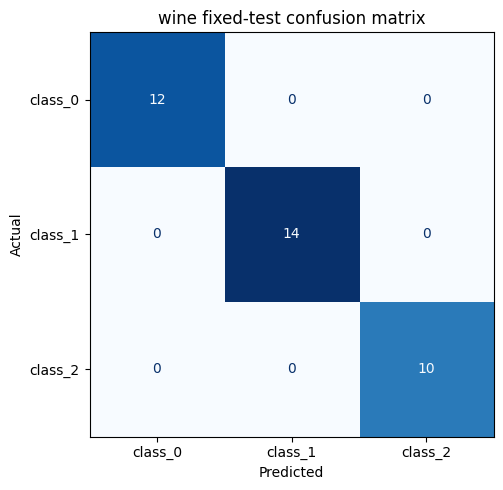

Wine class 0 one-vs-rest: 12 0 0 24
Manual precision, recall, F1: 1.0 1.0 1.0 ; report class: {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 12.0}


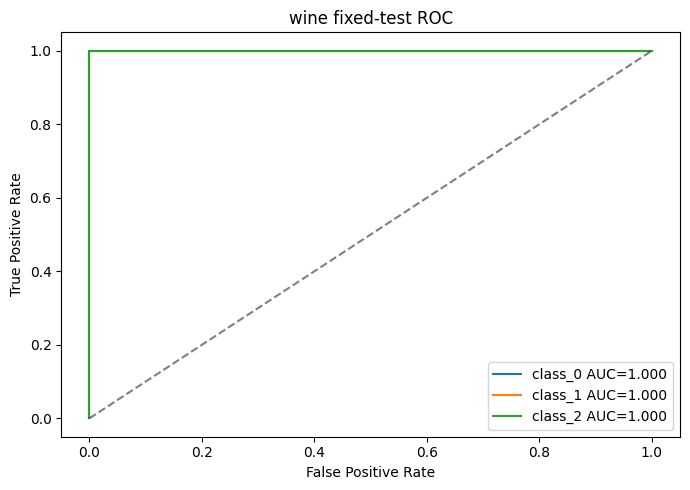

No test misclassifications. One error-free test does not prove perfect generalisation.
No off-diagonal errors.
Interpretation: Increasing a positive-class threshold generally reduces false positives but increases false negatives. Test metrics are descriptive; no retuning is done. Small validation splits and overlapping seeds limit inference.


In [9]:
algo=winner['algorithm'];rep=winner['representation'];param=winner['parameter'];model=fitted[(algo,rep,param)];test_x=prepared[42][rep][2];test_y=y_test
sc=scores(model,test_x,test_y,dataset);pred=model.predict(test_x);proba=model.predict_proba(test_x)
final=pd.DataFrame([dict(dataset=dataset,configuration_id=winner['configuration_id'],evaluation_seed=42,val_f1_mean=winner['val_f1_mean'],val_f1_std=winner['val_f1_std'],**{'test_'+k:v for k,v in sc.items()})]);display(final)
labels=list(model.classes_);names=list(bunch.target_names);report=classification_report(test_y,pred,labels=labels,target_names=names,zero_division=0,output_dict=True);display(pd.DataFrame(report).T)
cm=confusion_matrix(test_y,pred,labels=labels);fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay(cm,display_labels=names).plot(ax=ax,cmap='Blues',values_format='d',colorbar=False);ax.set_xlabel('Predicted');ax.set_ylabel('Actual');ax.set_title(dataset+' fixed-test confusion matrix');savefig(dataset+'_confusion_matrix.png')
if dataset=='breast_cancer':
 TP, FN, FP, TN=cm[0,0],cm[0,1],cm[1,0],cm[1,1];chosen=0
 print('Malignant positive: TP=',TP,'FN=',FN,'FP=',FP,'TN=',TN)
else:
 chosen=0;TP=cm[chosen,chosen];FN=cm[chosen,:].sum()-TP;FP=cm[:,chosen].sum()-TP;TN=cm.sum()-TP-FN-FP
 print('Wine class 0 one-vs-rest:',TP,FN,FP,TN)
manual_p=TP/(TP+FP) if TP+FP else np.nan;manual_r=TP/(TP+FN) if TP+FN else np.nan;manual_f=2*manual_p*manual_r/(manual_p+manual_r) if manual_p+manual_r else np.nan
print('Manual precision, recall, F1:',manual_p,manual_r,manual_f,'; report class:',report[names[chosen]])
fig,ax=plt.subplots(figsize=(7,5))
if dataset=='breast_cancer':
 fpr,tpr,_=roc_curve((test_y==0).astype(int),proba[:,labels.index(0)]);ax.plot(fpr,tpr,label=f'Malignant AUC={auc(fpr,tpr):.3f}')
else:
 for c in labels:
  fpr,tpr,_=roc_curve((test_y==c).astype(int),proba[:,labels.index(c)]);ax.plot(fpr,tpr,label=f'{names[c]} AUC={auc(fpr,tpr):.3f}')
ax.plot([0,1],[0,1],'k--',alpha=.5);ax.set_xlabel('False Positive Rate');ax.set_ylabel('True Positive Rate');ax.legend();ax.set_title(dataset+' fixed-test ROC');savefig(dataset+'_roc.png')
errors=np.flatnonzero(np.asarray(test_y)!=pred)
if len(errors):
 i=errors[0];print('Actual misclassification: original row index',test_x.index[i],'actual',test_y.iloc[i],'predicted',pred[i])
else:print('No test misclassifications. One error-free test does not prove perfect generalisation.')
if dataset=='wine':
 off=cm.copy();np.fill_diagonal(off,0)
 if off.max():r,c=np.unravel_index(off.argmax(),off.shape);print('Largest off-diagonal:',names[r],'misclassified as',names[c],off[r,c])
 else:print('No off-diagonal errors.')
print('Interpretation: Increasing a positive-class threshold generally reduces false positives but increases false negatives. Test metrics are descriptive; no retuning is done. Small validation splits and overlapping seeds limit inference.')
final.to_csv(ROOT/(dataset+'_classifier_test.csv'),index=False)

## 10. K-Means Clustering

,dataset,seed,representation,inertia,val_ari,val_silhouette,valid_silhouette
0,wine,42,unscaled,1.350496e+06,0.282836,0.486994,1
1,wine,42,scaled,8.747391e+02,1.000000,0.251637,1
2,wine,52,unscaled,1.303675e+06,0.400588,0.555887,1
3,wine,52,scaled,8.904355e+02,1.000000,0.301008,1
4,wine,62,unscaled,1.390754e+06,0.400588,0.686671,1
5,wine,62,scaled,8.722466e+02,1.000000,0.272587,1


,dataset,representation,inertia_mean,inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,valid_seed_count
0,wine,scaled,8.791404e+02,9.860948,1.000000,0.000000,0.275077,0.024780,3
1,wine,unscaled,1.348308e+06,43580.909759,0.361337,0.067984,0.576517,0.101425,3


Features selected using seed-42 training variance:
['proline', 'magnesium']
proline      93649.518162
magnesium      224.136572
dtype: float64
Interpretation: The two visualization features were selected using seed-42 training data only. Raw variance depends on measurement units, so this is a visualization choice, not a feature-importance ranking. K-Means was fitted using all original features.
Contingency unscaled


cluster_id,0,1,2
true_class,,,
0,2,10,0
1,5,0,9
2,7,0,3


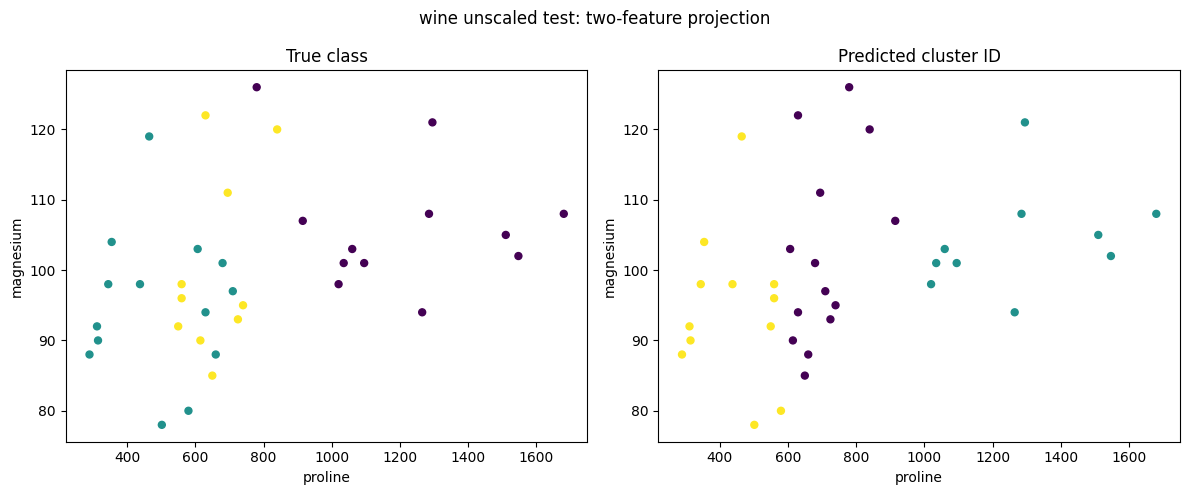

Contingency scaled


cluster_id,0,1,2
true_class,,,
0,12,0,0
1,1,13,0
2,0,0,10


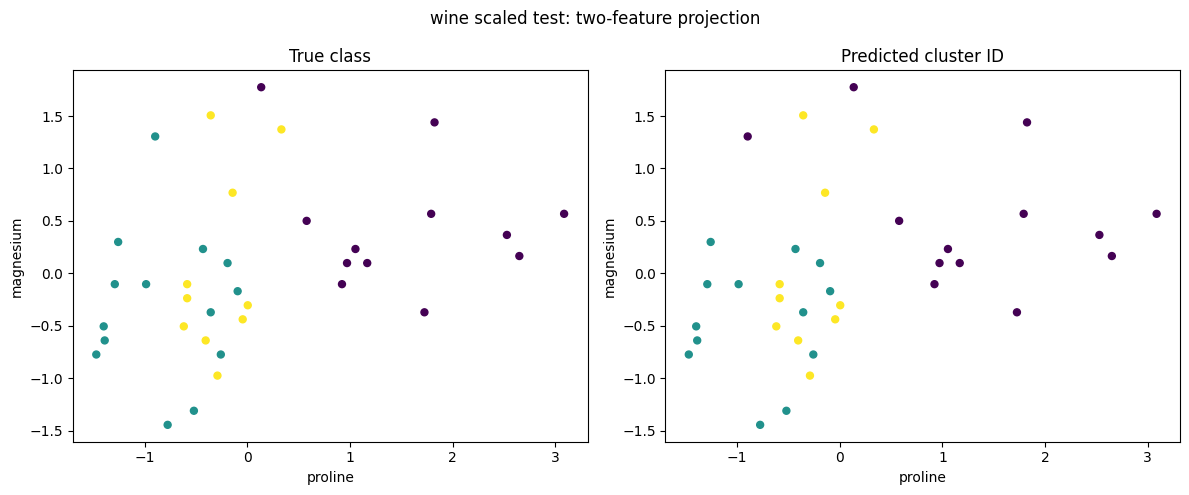

Interpretation: K-Means uses features without class labels for fitting; ARI uses labels only for evaluation. Cluster IDs do not equal class IDs. Silhouette scores are representation-dependent; inertia across differently scaled spaces is not directly comparable.


,dataset,representation,seed,test_cluster_counts,test_ari,test_silhouette
0,wine,unscaled,42,"{0: 14, 1: 10, 2: 12}",0.373323,0.49288
1,wine,scaled,42,"{0: 13, 1: 13, 2: 10}",0.908794,0.27112


In [10]:
km_runs=[];km_models={};km_tests=[]
for seed in SEEDS:
 for rep in ['unscaled','scaled']:
  a,b,_=prepared[seed][rep];km=KMeans(n_clusters=2 if dataset=='breast_cancer' else 3,random_state=seed,n_init=10);km.fit(a)
  if seed==42:km_models[rep]=km
  clusters=km.predict(b);km_runs.append(dict(dataset=dataset,seed=seed,representation=rep,inertia=km.inertia_,val_ari=adjusted_rand_score(splits[seed]['y_val'],clusters),val_silhouette=sil(b,clusters),valid_silhouette=int(np.isfinite(sil(b,clusters)))))
km_df=pd.DataFrame(km_runs);display(km_df);assert len(km_df)==6
km_summary=km_df.groupby(['dataset','representation'],as_index=False).agg(inertia_mean=('inertia','mean'),inertia_std=('inertia','std'),val_ari_mean=('val_ari','mean'),val_ari_std=('val_ari','std'),val_silhouette_mean=('val_silhouette','mean'),val_silhouette_std=('val_silhouette','std'),valid_seed_count=('valid_silhouette','sum'));display(km_summary)
# Features chosen from seed-42 training columns before test inspection, with no selection using test labels.

train_unscaled = prepared[42]['unscaled'][0]
feature_variances = train_unscaled.var(axis=0, ddof=1)
chosen_features = feature_variances.nlargest(2).index.tolist()

print("Features selected using seed-42 training variance:")
print(chosen_features)
print(feature_variances.loc[chosen_features])
print(
    "Interpretation: The two visualization features were selected "
    "using seed-42 training data only. Raw variance depends on "
    "measurement units, so this is a visualization choice, "
    "not a feature-importance ranking. "
    "K-Means was fitted using all original features."
)

for rep in ['unscaled','scaled']:
 xx=prepared[42][rep][2];cluster=km_models[rep].predict(xx);counts=pd.Series(cluster).value_counts().sort_index().to_dict();ari=adjusted_rand_score(y_test,cluster);ss=sil(xx,cluster)
 km_tests.append(dict(dataset=dataset,representation=rep,seed=42,test_cluster_counts=str(counts),test_ari=ari,test_silhouette=ss))
 contingency=pd.crosstab(pd.Series(y_test.to_numpy(),name='true_class'),pd.Series(cluster,name='cluster_id'));print('Contingency',rep);display(contingency)
 fig,axes=plt.subplots(1,2,figsize=(12,5))
 for ax,labels_,title in [(axes[0],y_test.to_numpy(),'True class'),(axes[1],cluster,'Predicted cluster ID')]:
  ax.scatter(xx[chosen_features[0]],xx[chosen_features[1]],c=labels_,cmap='viridis',s=25);ax.set_title(title);ax.set_xlabel(chosen_features[0]);ax.set_ylabel(chosen_features[1])
 fig.suptitle(dataset+' '+rep+' test: two-feature projection');savefig(dataset+'_clusters_'+rep+'.png')
print('Interpretation: K-Means uses features without class labels for fitting; ARI uses labels only for evaluation. Cluster IDs do not equal class IDs. Silhouette scores are representation-dependent; inertia across differently scaled spaces is not directly comparable.')
km_test=pd.DataFrame(km_tests);display(km_test)
km_df.to_csv(ROOT/(dataset+'_kmeans_runs.csv'),index=False);km_summary.to_csv(ROOT/(dataset+'_kmeans_summary.csv'),index=False);km_test.to_csv(ROOT/(dataset+'_kmeans_test.csv'),index=False)